# Stochastic Gradient Descent on Linear Regression

Predicting how crowded a university gym is, from 62,185 observations taken roughly every ten minutes over a year at a campus gym. The target is `number_people`; the predictors are time of day, day of week, month, holiday and semester flags, and outdoor temperature.

The subject is the optimiser rather than the problem. Linear regression has a closed-form solution, so stochastic gradient descent is never *necessary* at this size, and section 7 times both to show exactly how unnecessary. What SGD is good for is demonstrating things that stay true at scales where the closed form is impossible:

1. **Scaling is not optional.** `timestamp` runs to 86,400 while `is_weekend` is 0 or 1. Section 5 runs SGD on both versions of the same data and the difference is not subtle.
2. **The learning rate can destroy the fit.** Section 6 sweeps `eta0` until the model diverges, and reports the point where it does.
3. **Convergence is something you watch, not assume.** Section 6 tracks loss per epoch rather than trusting that `max_iter` was enough.

There is also a modelling problem worth getting right on the way. Hour of day is cyclical: hour 23 and hour 0 are one hour apart, and a linear coefficient on `hour` cannot know that. Section 4 fixes it with a sine and cosine pair and measures what the fix is worth.

In [37]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

# plain matplotlib styling, so the notebook carries no seaborn dependency
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.facecolor'] = 'white'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas      ', pd.__version__)
print('numpy       ', np.__version__)
print('scikit-learn', sklearn.__version__)

pandas       2.2.3
numpy        2.2.4
scikit-learn 1.6.1


## 1. Load and profile

In [38]:
gym = pd.read_csv('crowdness_gym_data.csv', parse_dates=['date'])
print('Shape:', gym.shape)
gym.head()

Shape: (62184, 11)


,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


In [39]:
gym.info()
print()
print(gym.describe().T.round(3).to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  object 
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 5.2+ MB

                        count       mean        std    min      25%       50%       75%       max
number_people         62184.0     29.073     22.689   0.00      9.0

In [40]:
print('Missing values:', int(gym.isnull().sum().sum()))
print('Duplicate rows:', int(gym.duplicated().sum()))
print()
print('Date range:', gym['date'].min(), 'to', gym['date'].max())
print('Span:', (gym['date'].max() - gym['date'].min()).days, 'days')
print('Observations per day on average:', round(len(gym) / max((gym['date'].max() - gym['date'].min()).days, 1), 1))
print()
for col in ['is_weekend', 'is_holiday', 'is_start_of_semester', 'is_during_semester']:
    print(col + ':', dict(gym[col].value_counts()))

Missing values: 0
Duplicate rows: 0

Date range: 2015-08-14 17:00:11-07:00 to 2017-03-18 19:22:51-07:00
Span: 582 days
Observations per day on average: 106.8

is_weekend: {0: np.int64(44594), 1: np.int64(17590)}
is_holiday: {0: np.int64(62024), 1: np.int64(160)}
is_start_of_semester: {0: np.int64(57282), 1: np.int64(4902)}
is_during_semester: {1: np.int64(41055), 0: np.int64(21129)}


### A redundancy worth catching before modelling

`timestamp` is seconds elapsed since midnight and `hour` is the hour of day. One is a deterministic function of the other, so including both hands the model the same information twice on wildly different scales. `date` carries it a third time, along with the `month` already present as its own column.

This is not a disaster for a regularised linear model, but it inflates the feature count, makes coefficients uninterpretable, and on an unscaled matrix it is the single worst offender for gradient descent, since `timestamp` has by far the largest magnitude of anything in the data.

In [41]:
print('Correlation between timestamp and hour:', round(gym['timestamp'].corr(gym['hour']), 6))
print()
print('timestamp range:', gym['timestamp'].min(), 'to', gym['timestamp'].max())
print('hour range:     ', gym['hour'].min(), 'to', gym['hour'].max())
print('86400 seconds in a day, so timestamp is seconds since midnight.')
print()
print('timestamp / 3600 against hour, first few rows:')
chk = pd.DataFrame({'timestamp': gym['timestamp'].head(6),
                    'timestamp_over_3600': (gym['timestamp'] / 3600).round(3).head(6),
                    'hour': gym['hour'].head(6)})
print(chk.to_string(index=False))
print()
print('Scale range across the raw predictors, which is what SGD has to cope with:')
raw_feats = ['timestamp', 'day_of_week', 'is_weekend', 'is_holiday', 'temperature',
             'is_start_of_semester', 'is_during_semester', 'month', 'hour']
scales = pd.DataFrame({'min': gym[raw_feats].min(), 'max': gym[raw_feats].max(),
                       'std': gym[raw_feats].std().round(3)})
scales['range'] = scales['max'] - scales['min']
print(scales.to_string())
print()
print('Ratio of largest to smallest feature standard deviation:',
      round(gym[raw_feats].std().max() / gym[raw_feats].std().min(), 1))

Correlation between timestamp and hour: 0.999077



timestamp range: 0 to 86399
hour range:      0 to 23
86400 seconds in a day, so timestamp is seconds since midnight.

timestamp / 3600 against hour, first few rows:
 timestamp  timestamp_over_3600  hour
     61211               17.003    17
     62414               17.337    17
     63015               17.504    17
     63616               17.671    17
     64217               17.838    17
     64818               18.005    18

Scale range across the raw predictors, which is what SGD has to cope with:
                        min       max        std     range
timestamp              0.00  86399.00  24211.276  86399.00
day_of_week            0.00      6.00      1.997      6.00
is_weekend             0.00      1.00      0.450      1.00
is_holiday             0.00      1.00      0.051      1.00
temperature           38.14     87.17      6.316     49.03
is_start_of_semester   0.00      1.00      0.269      1.00
is_during_semester     0.00      1.00      0.474      1.00
month                

## 2. The target

count    62184.000
mean        29.073
std         22.689
min          0.000
25%          9.000
50%         28.000
75%         43.000
max        145.000

Skew: 0.5651
Share of observations with zero people: 14.11%


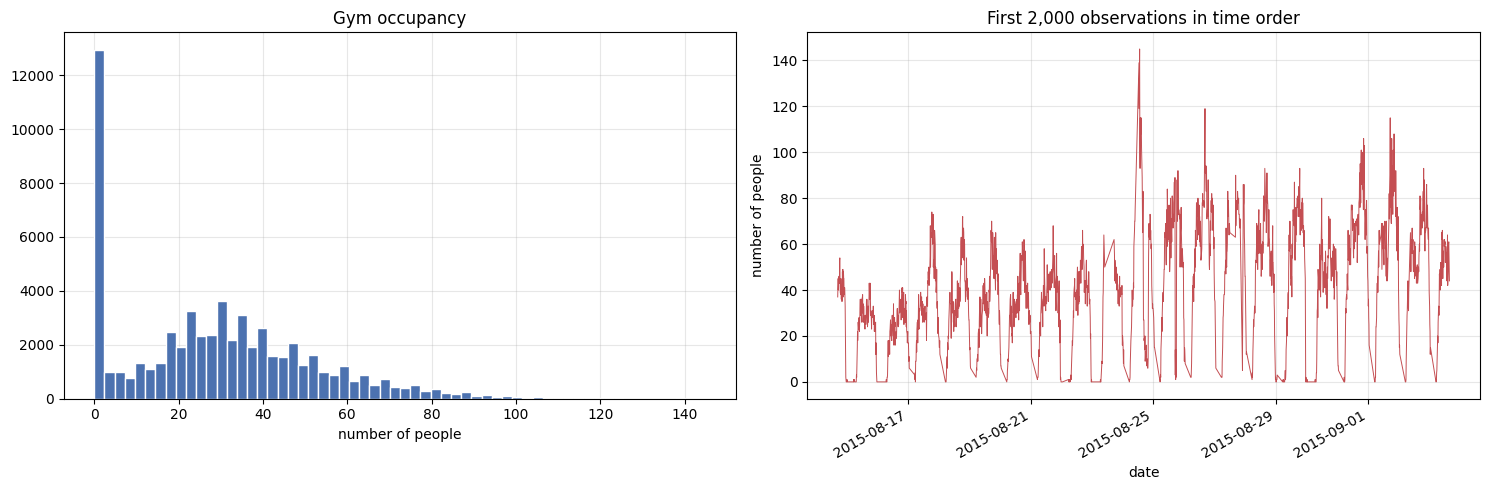

In [42]:
print(gym['number_people'].describe().round(3).to_string())
print()
print('Skew:', round(gym['number_people'].skew(), 4))
print('Share of observations with zero people:',
      str(round(100 * (gym['number_people'] == 0).mean(), 2)) + '%')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(gym['number_people'], bins=60, color='#4C72B0', edgecolor='white')
axes[0].set_xlabel('number of people')
axes[0].set_title('Gym occupancy')
axes[1].plot(gym['date'].values[:2000], gym['number_people'].values[:2000], linewidth=0.7, color='#C44E52')
axes[1].set_title('First 2,000 observations in time order')
axes[1].set_xlabel('date')
axes[1].set_ylabel('number of people')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

## 3. Exploratory analysis

The single most important plot in this notebook is occupancy against hour of day, because it decides how `hour` has to be encoded.

Occupancy by hour of day:
      mean_people  median_people     n
hour                                  
0           14.72           11.0  2978
1            2.40            0.0  1782
2            0.18            0.0  1520
3            0.15            0.0  1517
4            0.28            0.0  1437
5            1.05            1.0  2441
6            8.76            8.0  2758
7           15.39           15.0  2791
8           24.05           23.0  2798
9           30.19           29.0  2799
10          33.73           32.0  2796
11          36.22           33.0  2791
12          36.11           33.0  2805
13          34.57           32.0  2812
14          33.93           31.0  2787
15          37.20           34.0  2778
16          42.96           39.0  2808
17          47.64           44.0  2911
18          48.30           45.0  2837
19          44.74           42.0  2819
20          41.67           40.0  2795
21          42.92           40.0  2779
22          40.46           38.0  2775

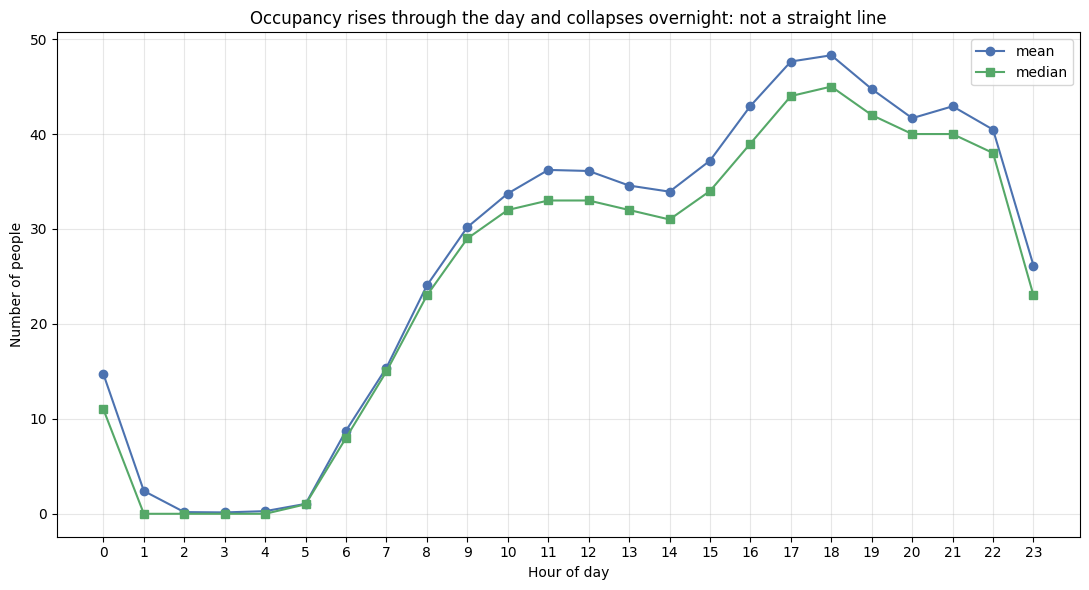


Peak hour: 18 with 48.3 people on average
Quietest hour: 3 with 0.1

A single linear coefficient on `hour` is forced to fit a straight line through that curve.


In [43]:
by_hour = gym.groupby('hour')['number_people'].agg(['mean', 'median', 'count'])
by_hour.columns = ['mean_people', 'median_people', 'n']
print('Occupancy by hour of day:')
print(by_hour.round(2).to_string())

plt.figure(figsize=(11, 6))
plt.plot(by_hour.index, by_hour['mean_people'], marker='o', color='#4C72B0', label='mean')
plt.plot(by_hour.index, by_hour['median_people'], marker='s', color='#55A868', label='median')
plt.xlabel('Hour of day')
plt.ylabel('Number of people')
plt.title('Occupancy rises through the day and collapses overnight: not a straight line')
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

print()
print('Peak hour:', int(by_hour['mean_people'].idxmax()), 'with', round(by_hour['mean_people'].max(), 1), 'people on average')
print('Quietest hour:', int(by_hour['mean_people'].idxmin()), 'with', round(by_hour['mean_people'].min(), 1))
print()
print('A single linear coefficient on `hour` is forced to fit a straight line through that curve.')

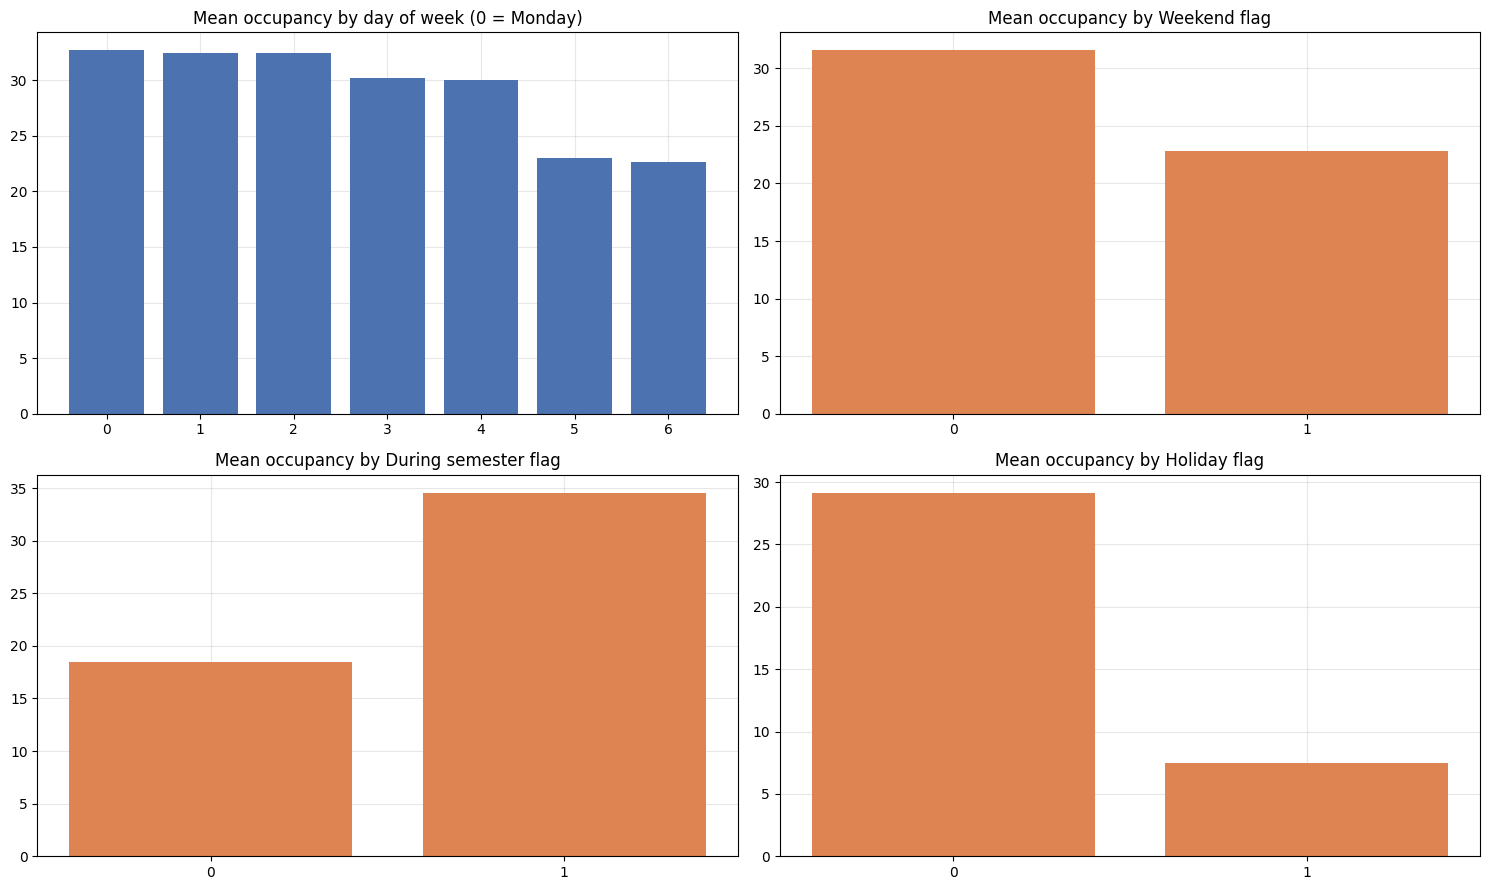

Mean occupancy by flag:
  is_weekend             0: 31.55    1: 22.79
  is_holiday             0: 29.13    1: 7.52
  is_start_of_semester   0: 27.86    1: 43.24
  is_during_semester     0: 18.47    1: 34.53

Correlation of each raw predictor with occupancy:
hour                    0.5520
timestamp               0.5502
temperature             0.3733
is_during_semester      0.3354
is_start_of_semester    0.1827
is_weekend             -0.1740
day_of_week            -0.1621
month                  -0.0979
is_holiday             -0.0482


In [44]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

bd = gym.groupby('day_of_week')['number_people'].mean()
axes[0, 0].bar([str(i) for i in bd.index], bd.values, color='#4C72B0')
axes[0, 0].set_title('Mean occupancy by day of week (0 = Monday)')

for flag, ax, title in [('is_weekend', axes[0, 1], 'Weekend'),
                        ('is_during_semester', axes[1, 0], 'During semester'),
                        ('is_holiday', axes[1, 1], 'Holiday')]:
    g = gym.groupby(flag)['number_people'].mean()
    ax.bar([str(i) for i in g.index], g.values, color='#DD8452')
    ax.set_title('Mean occupancy by ' + title + ' flag')

plt.tight_layout()
plt.show()

print('Mean occupancy by flag:')
for flag in ['is_weekend', 'is_holiday', 'is_start_of_semester', 'is_during_semester']:
    g = gym.groupby(flag)['number_people'].mean()
    print('  ' + flag.ljust(22) + ' 0: ' + str(round(g.get(0, float('nan')), 2)).ljust(8) + ' 1: ' + str(round(g.get(1, float('nan')), 2)))
print()
print('Correlation of each raw predictor with occupancy:')
print(gym[raw_feats + ['number_people']].corr()['number_people'].drop('number_people').round(4).sort_values(key=np.abs, ascending=False).to_string())

## 4. Feature engineering: cyclical time

Hour, month and day of week all wrap around. Hour 23 is one hour from hour 0, December is one month from January, Sunday is one day from Monday. Encoding them as plain integers tells a linear model that hour 23 is 23 units from hour 0, which is false, and the model cannot recover from it.

The standard fix maps each cyclical variable onto a circle with a sine and cosine pair, so that the distance between hour 23 and hour 0 is small in both components. Three feature sets are built and compared:

- **A, raw**: every column as given, including both `timestamp` and `hour`.
- **B, cyclical**: `timestamp` dropped as redundant, cyclical variables replaced by sine and cosine pairs.
- **C, one-hot hour**: as B but with hour as 24 indicator columns, which can fit any shape of daily curve at the cost of 24 parameters.

In [45]:
def cyc(values, period):
    ang = 2 * np.pi * values / period
    return np.sin(ang), np.cos(ang)

base = gym.drop(columns=['date'])

# A: raw, exactly as the file provides
X_A = base.drop(columns=['number_people']).astype(float)

# B: cyclical encoding, redundant timestamp dropped
B = base.drop(columns=['number_people', 'timestamp']).copy()
B['hour_sin'], B['hour_cos'] = cyc(B['hour'], 24)
B['month_sin'], B['month_cos'] = cyc(B['month'], 12)
B['dow_sin'], B['dow_cos'] = cyc(B['day_of_week'], 7)
X_B = B.drop(columns=['hour', 'month', 'day_of_week']).astype(float)

# C: as B but hour as 24 indicators
C = B.drop(columns=['hour_sin', 'hour_cos'])
C = pd.concat([C, pd.get_dummies(gym['hour'], prefix='h').astype(float)], axis=1)
X_C = C.drop(columns=['hour', 'month', 'day_of_week']).astype(float)

y = gym['number_people'].astype(float)

for name, Xv in [('A raw', X_A), ('B cyclical', X_B), ('C one-hot hour', X_C)]:
    print(name.ljust(16) + str(Xv.shape) + '  columns: ' + ', '.join(list(Xv.columns)[:8]) + (' ...' if Xv.shape[1] > 8 else ''))

A raw           (62184, 9)  columns: timestamp, day_of_week, is_weekend, is_holiday, temperature, is_start_of_semester, is_during_semester, month ...
B cyclical      (62184, 11)  columns: is_weekend, is_holiday, temperature, is_start_of_semester, is_during_semester, hour_sin, hour_cos, month_sin ...
C one-hot hour  (62184, 33)  columns: is_weekend, is_holiday, temperature, is_start_of_semester, is_during_semester, month_sin, month_cos, dow_sin ...


## 5. The scaling lesson

Here is the point of the project. The same `SGDRegressor`, the same data, the same step size, the same number of epochs, run on the unscaled matrix and then on the standardised one.

Gradient descent takes a step proportional to the gradient, and the gradient with respect to a feature is proportional to that feature's magnitude. `timestamp` has a standard deviation of 24,211 while `is_holiday` has one of 0.051, a ratio of roughly 478,000 to 1. The loss surface is therefore an extremely long, narrow valley: a step size small enough to be stable along the `timestamp` axis makes almost no progress along the others, and a step size large enough to move the others overshoots catastrophically along `timestamp`. Standardising makes the valley round, so one step size works for every direction.

The step size used below, `eta0 = 1e-4`, was chosen because it is stable on the standardised data. It is the same value in both runs, so the only difference between them is the scaling.

The closed-form solution is immune to all of this, which is why `LinearRegression` is the reference. Any gap between it and SGD is the optimiser failing, not the model being wrong.

In [46]:
X_train_A, X_test_A, y_train, y_test = train_test_split(X_A, y, test_size=0.2, random_state=RANDOM_STATE)

ETA = 1e-4
results = []

def report(name, pred, note=''):
    pred = np.asarray(pred, dtype=float)
    if not np.all(np.isfinite(pred)) or np.abs(pred).max() > 1e6:
        results.append({'model': name, 'rmse': 'diverged', 'mae': 'diverged', 'r2': 'diverged'})
        print(name.ljust(44) + 'DIVERGED  (largest prediction ' + '{:.3e}'.format(np.nanmax(np.abs(pred))) + ' people)')
        return None
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results.append({'model': name, 'rmse': round(rmse, 4), 'mae': round(mae, 4), 'r2': round(r2, 4)})
    print(name.ljust(44) + 'RMSE ' + str(round(rmse, 3)).ljust(9) + 'MAE ' + str(round(mae, 3)).ljust(9) + 'R2 ' + str(round(r2, 4)) + ('  ' + note if note else ''))
    return r2

report('Baseline: predict the training mean', np.full(len(y_test), y_train.mean()))

ols = LinearRegression().fit(X_train_A, y_train)
ols_r2 = report('Closed-form OLS on raw features', ols.predict(X_test_A), '(reference: immune to scaling)')

sgd_unscaled = SGDRegressor(max_iter=50, tol=None, eta0=ETA, learning_rate='constant',
                            random_state=RANDOM_STATE)
with np.errstate(all='ignore'):
    sgd_unscaled.fit(X_train_A, y_train)
    pred_un = sgd_unscaled.predict(X_test_A)
un_r2 = report('SGD on UNSCALED features', pred_un)

sgd_scaled = Pipeline([('scale', StandardScaler()),
                       ('model', SGDRegressor(max_iter=50, tol=None, eta0=ETA,
                                              learning_rate='constant', random_state=RANDOM_STATE))])
sgd_scaled.fit(X_train_A, y_train)
sc_r2 = report('SGD on SCALED features', sgd_scaled.predict(X_test_A))

print()
print('Identical optimiser, identical eta0 of ' + str(ETA) + ', identical 50 epochs.')
print('The only difference is whether the features were standardised first.')
print()
print('Largest absolute coefficient:')
print('  unscaled SGD: ' + '{:.3e}'.format(np.abs(sgd_unscaled.coef_).max()))
print('  scaled SGD:   ' + str(round(float(np.abs(sgd_scaled.named_steps['model'].coef_).max()), 4)))
print('  closed form:  ' + '{:.3e}'.format(np.abs(ols.coef_).max()))
print()
if sc_r2 is not None and ols_r2 is not None:
    print('R2 gap, closed form minus scaled SGD:', round(ols_r2 - sc_r2, 4))
    print('Scaled SGD recovers ' + str(round(100 * sc_r2 / ols_r2, 1)) + '% of the closed-form R2.')

Baseline: predict the training mean         RMSE 22.734   MAE 18.376   R2 -0.0
Closed-form OLS on raw features             RMSE 15.83    MAE 12.09    R2 0.5152  (reference: immune to scaling)


SGD on UNSCALED features                    DIVERGED  (largest prediction 4.467e+17 people)


SGD on SCALED features                      RMSE 15.844   MAE 12.109   R2 0.5143

Identical optimiser, identical eta0 of 0.0001, identical 50 epochs.
The only difference is whether the features were standardised first.

Largest absolute coefficient:
  unscaled SGD: 5.171e+12
  scaled SGD:   9.2128
  closed form:  1.317e+01

R2 gap, closed form minus scaled SGD: 0.0008
Scaled SGD recovers 99.8% of the closed-form R2.


## 6. Learning rate and convergence

Two questions the default settings hide. How large can the step size be before the optimiser stops converging, and how many epochs does it actually need?

In [47]:
etas = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0]
rows = []
for eta in etas:
    p = Pipeline([('scale', StandardScaler()),
                  ('model', SGDRegressor(max_iter=50, tol=None, eta0=eta,
                                         learning_rate='constant', random_state=RANDOM_STATE))])
    with np.errstate(all='ignore'):
        p.fit(X_train_A, y_train)
        pred = np.asarray(p.predict(X_test_A), dtype=float)
    ok = np.all(np.isfinite(pred)) and np.abs(pred).max() < 1e6
    rows.append({'eta0': eta,
                 'test_r2': round(r2_score(y_test, pred), 4) if ok else 'diverged',
                 'max_abs_coef': round(float(np.abs(p.named_steps['model'].coef_).max()), 3) if ok else 'overflow',
                 'converged': ok})

eta_tbl = pd.DataFrame(rows).set_index('eta0')
print('Constant learning rate sweep, 50 epochs on SCALED features:')
print(eta_tbl.to_string())
print()
ok_rows = eta_tbl[eta_tbl['converged']]
if len(ok_rows):
    best_eta = ok_rows['test_r2'].astype(float).idxmax()
    print('Best eta0 among those that converged:', best_eta,
          'with R2', ok_rows.loc[best_eta, 'test_r2'])
    print('Too small (' + str(etas[0]) + ') and 50 epochs are not enough to move the weights far from zero.')
bad = eta_tbl[~eta_tbl['converged']]
print('Diverged at eta0:', list(bad.index) if len(bad) else 'none in this range')
print()
print('The usable window is narrow, and it sits several orders of magnitude below the')
print('scikit-learn default of eta0=0.01. A default is not a safe choice.')

Constant learning rate sweep, 50 epochs on SCALED features:
               test_r2 max_abs_coef  converged
eta0                                          
1.000000e-07   -0.6823        2.412       True
1.000000e-06    0.5022         5.66       True
1.000000e-05    0.5142        5.985       True
1.000000e-04    0.5143        9.213       True
1.000000e-03    0.5112       20.129       True
1.000000e-02  diverged     overflow      False
1.000000e-01  diverged     overflow      False
1.000000e+00  diverged     overflow      False

Best eta0 among those that converged: 0.0001 with R2 0.5143
Too small (1e-07) and 50 epochs are not enough to move the weights far from zero.
Diverged at eta0: [0.01, 0.1, 1.0]

The usable window is narrow, and it sits several orders of magnitude below the
scikit-learn default of eta0=0.01. A default is not a safe choice.


In [48]:
schedules = ['constant', 'optimal', 'invscaling', 'adaptive']
rows = []
for sch in schedules:
    p = Pipeline([('scale', StandardScaler()),
                  ('model', SGDRegressor(max_iter=50, tol=None, eta0=1e-4,
                                         learning_rate=sch, random_state=RANDOM_STATE))])
    with np.errstate(all='ignore'):
        p.fit(X_train_A, y_train)
        pred = np.asarray(p.predict(X_test_A), dtype=float)
    ok = np.all(np.isfinite(pred)) and np.abs(pred).max() < 1e6
    rows.append({'schedule': sch,
                 'test_r2': round(r2_score(y_test, pred), 4) if ok else 'diverged',
                 'epochs_run': int(p.named_steps['model'].n_iter_)})

print('Learning rate schedules, 50 epochs, eta0 = 1e-4, scaled features:')
print(pd.DataFrame(rows).set_index('schedule').to_string())
print()
print('Closed-form OLS R2 for reference:', round(ols_r2, 4))
print()
print("Note that 'optimal' diverged. It is the one schedule that IGNORES eta0 entirely:")
print('it sets the rate to 1 / (alpha * (t + t0)), so with the default alpha of 1e-4 the')
print('initial step is enormous regardless of what eta0 was passed. Passing eta0 alongside')
print("learning_rate='optimal' looks like it configures the optimiser and does nothing.")
print()
print("'invscaling' and 'adaptive' both decay or back off from eta0 and both converged,")
print('landing within 0.0002 R2 of the constant schedule.')

Learning rate schedules, 50 epochs, eta0 = 1e-4, scaled features:
             test_r2  epochs_run
schedule                        
constant      0.5143          50
optimal     diverged          50
invscaling    0.5141          50
adaptive      0.5143          50

Closed-form OLS R2 for reference: 0.5152

Note that 'optimal' diverged. It is the one schedule that IGNORES eta0 entirely:
it sets the rate to 1 / (alpha * (t + t0)), so with the default alpha of 1e-4 the
initial step is enormous regardless of what eta0 was passed. Passing eta0 alongside
learning_rate='optimal' looks like it configures the optimiser and does nothing.

'invscaling' and 'adaptive' both decay or back off from eta0 and both converged,
landing within 0.0002 R2 of the constant schedule.


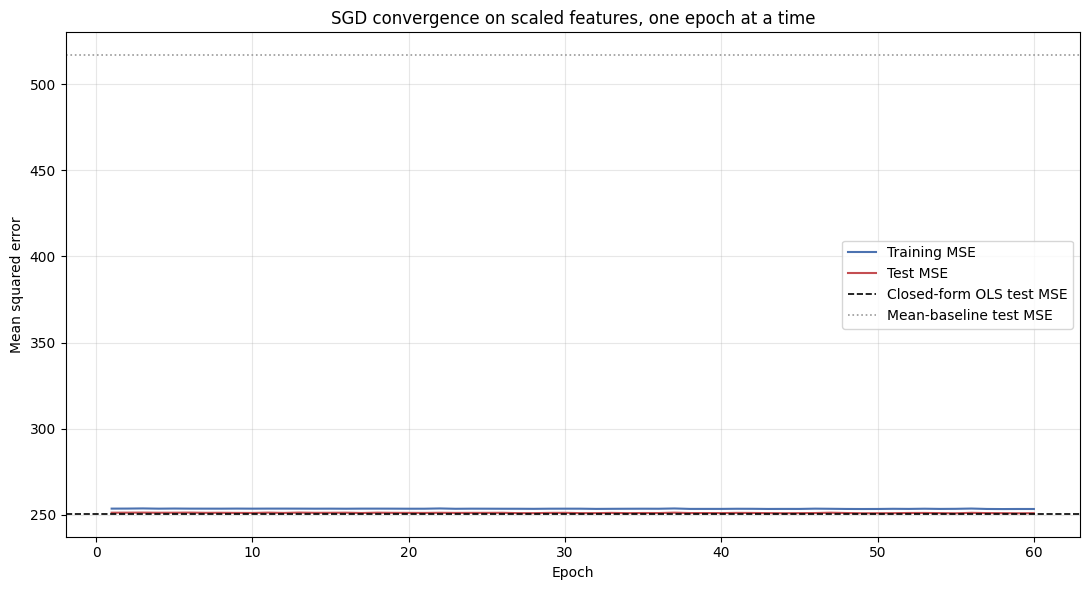

Test MSE after epoch  1: 251.2267
Test MSE after epoch  5: 251.2241
Test MSE after epoch 10: 251.0842
Test MSE after epoch 20: 251.1319
Test MSE after epoch 40: 251.0054
Test MSE after epoch 60: 250.955

Closed-form OLS test MSE:  250.5929
Mean-baseline test MSE:    516.8491

Improvement from epoch 20 to epoch 60: 0.176857
Gap still remaining to the closed form: 0.362105

Note that train and test curves sit on top of each other throughout. With 49,747
rows and 9 features there is no capacity to overfit, so early stopping would buy
nothing here; the only question is whether it has converged yet.


In [49]:
# Watch convergence explicitly with partial_fit, one epoch at a time
scaler = StandardScaler().fit(X_train_A)
Xtr = scaler.transform(X_train_A)
Xte = scaler.transform(X_test_A)

sgd = SGDRegressor(eta0=1e-4, learning_rate='constant', random_state=RANDOM_STATE)
rng = np.random.RandomState(RANDOM_STATE)
n = Xtr.shape[0]
train_curve, test_curve = [], []
EPOCHS = 60

for epoch in range(EPOCHS):
    idx = rng.permutation(n)
    sgd.partial_fit(Xtr[idx], y_train.values[idx])
    train_curve.append(mean_squared_error(y_train, sgd.predict(Xtr)))
    test_curve.append(mean_squared_error(y_test, sgd.predict(Xte)))

ols_mse = mean_squared_error(y_test, ols.predict(X_test_A))
base_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))

plt.figure(figsize=(11, 6))
plt.plot(range(1, EPOCHS + 1), train_curve, label='Training MSE', color='#4C72B0')
plt.plot(range(1, EPOCHS + 1), test_curve, label='Test MSE', color='#C44E52')
plt.axhline(ols_mse, color='black', linestyle='--', linewidth=1.2, label='Closed-form OLS test MSE')
plt.axhline(base_mse, color='#999999', linestyle=':', linewidth=1.2, label='Mean-baseline test MSE')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.title('SGD convergence on scaled features, one epoch at a time')
plt.legend()
plt.tight_layout()
plt.show()

for e in [1, 5, 10, 20, 40, EPOCHS]:
    print('Test MSE after epoch ' + str(e).rjust(2) + ': ' + str(round(test_curve[e - 1], 4)))
print()
print('Closed-form OLS test MSE: ', round(ols_mse, 4))
print('Mean-baseline test MSE:   ', round(base_mse, 4))
print()
print('Improvement from epoch 20 to epoch ' + str(EPOCHS) + ':', round(test_curve[19] - test_curve[-1], 6))
print('Gap still remaining to the closed form:', round(test_curve[-1] - ols_mse, 6))
print()
print('Note that train and test curves sit on top of each other throughout. With 49,747')
print('rows and 9 features there is no capacity to overfit, so early stopping would buy')
print('nothing here; the only question is whether it has converged yet.')

## 7. Does SGD actually buy anything here?

SGD exists because the closed form requires inverting a matrix built from the whole dataset, which becomes impossible when the data does not fit in memory. At 62,185 rows and 10 features, it fits comfortably. Timing both makes the trade concrete rather than theoretical.

In [50]:
def timeit(fn, repeats=3):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return min(ts)

t_ols = timeit(lambda: LinearRegression().fit(X_train_A, y_train))
t_sgd = timeit(lambda: Pipeline([('scale', StandardScaler()),
                                 ('model', SGDRegressor(max_iter=50, tol=None, eta0=1e-4,
                                                        learning_rate='constant',
                                                        random_state=RANDOM_STATE))]).fit(X_train_A, y_train))

print('Training rows:', X_train_A.shape[0], ' features:', X_train_A.shape[1])
print()
print('Closed-form OLS fit time: ' + str(round(t_ols * 1000, 2)) + ' ms')
print('SGD (50 epochs) fit time: ' + str(round(t_sgd * 1000, 2)) + ' ms')
print('SGD is ' + str(round(t_sgd / t_ols, 1)) + 'x slower at this size')
print()
print('And it reaches a slightly worse solution, per section 6.')
print('The honest conclusion: at this scale SGD is a demonstration, not a tool.')
print('Its advantage is that its cost per step does not depend on the number of rows,')
print('so it keeps working when the closed form cannot be computed at all.')
print()
cmp = pd.DataFrame({
    'coefficient_OLS': ols.coef_,
    'coefficient_SGD_scaled_back': sgd.coef_ / scaler.scale_
}, index=X_A.columns)
cmp['abs_diff'] = (cmp['coefficient_OLS'] - cmp['coefficient_SGD_scaled_back']).abs()
print('Coefficients, closed form against SGD converted back to raw units:')
print(cmp.round(4).to_string())

Training rows: 49747  features: 9

Closed-form OLS fit time: 7.28 ms
SGD (50 epochs) fit time: 210.47 ms
SGD is 28.9x slower at this size

And it reaches a slightly worse solution, per section 6.
The honest conclusion: at this scale SGD is a demonstration, not a tool.
Its advantage is that its cost per step does not depend on the number of rows,
so it keeps working when the closed form cannot be computed at all.

Coefficients, closed form against SGD converted back to raw units:
                      coefficient_OLS  coefficient_SGD_scaled_back  abs_diff
timestamp                     -0.0005                       0.0001    0.0006
day_of_week                   -0.8661                      -0.8342    0.0319
is_weekend                    -5.5026                      -5.4898    0.0128
is_holiday                   -13.1674                     -12.1121    1.0553
temperature                    0.8635                       0.8485    0.0150
is_start_of_semester           6.7757                 

## 8. Do the cyclical features earn their place?

All three feature sets, same folds, Ridge as the estimator so the comparison is about the features rather than the optimiser.

In [51]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, Xv in [('A raw (timestamp + hour)', X_A), ('B cyclical sin/cos', X_B), ('C one-hot hour', X_C)]:
    p = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
    s = cross_val_score(p, Xv, y, cv=kf, scoring='r2')
    rows.append({'feature_set': name, 'n_features': Xv.shape[1],
                 'cv_r2_mean': round(s.mean(), 4), 'cv_r2_std': round(s.std(), 4)})

feat_tbl = pd.DataFrame(rows).set_index('feature_set')
print('Ridge on each feature set, 5-fold cross-validation:')
print(feat_tbl.to_string())
print()
print('Gain from cyclical encoding (B minus A):', round(feat_tbl.iloc[1]['cv_r2_mean'] - feat_tbl.iloc[0]['cv_r2_mean'], 4))
print('Further gain from one-hot hour (C minus B):', round(feat_tbl.iloc[2]['cv_r2_mean'] - feat_tbl.iloc[1]['cv_r2_mean'], 4))

Ridge on each feature set, 5-fold cross-validation:
                          n_features  cv_r2_mean  cv_r2_std
feature_set                                                
A raw (timestamp + hour)           9      0.5092     0.0034
B cyclical sin/cos                11      0.5212     0.0023
C one-hot hour                    33      0.6068     0.0026

Gain from cyclical encoding (B minus A): 0.012
Further gain from one-hot hour (C minus B): 0.0856


In [52]:
best_set = feat_tbl['cv_r2_mean'].idxmax()
X_best = {'A raw (timestamp + hour)': X_A, 'B cyclical sin/cos': X_B, 'C one-hot hour': X_C}[best_set]
print('Best feature set:', best_set)
print()

Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_best, y, test_size=0.2, random_state=RANDOM_STATE)

for label, model in [('Ridge on best feature set', Ridge(alpha=1.0, random_state=RANDOM_STATE)),
                     ('SGD on best feature set', SGDRegressor(max_iter=200, tol=1e-4, eta0=0.01,
                                                              learning_rate='adaptive', random_state=RANDOM_STATE))]:
    p = Pipeline([('scale', StandardScaler()), ('model', model)])
    p.fit(Xb_train, yb_train)
    pred = p.predict(Xb_test)
    rmse = np.sqrt(mean_squared_error(yb_test, pred))
    print(label.ljust(34) + 'RMSE ' + str(round(rmse, 3)).ljust(10) + 'MAE ' + str(round(mean_absolute_error(yb_test, pred), 3)).ljust(10) + 'R2 ' + str(round(r2_score(yb_test, pred), 4)))

rf = RandomForestRegressor(n_estimators=120, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(Xb_train, yb_train)
pred_rf = rf.predict(Xb_test)
print('Random forest (non-linear reference)'.ljust(34) + 'RMSE ' + str(round(np.sqrt(mean_squared_error(yb_test, pred_rf)), 3)).ljust(10) + 'MAE ' + str(round(mean_absolute_error(yb_test, pred_rf), 3)).ljust(10) + 'R2 ' + str(round(r2_score(yb_test, pred_rf), 4)))
print()
print('The random forest gap measures how much of the signal is non-linear and therefore')
print('out of reach of any linear model, however well optimised.')

Best feature set: C one-hot hour

Ridge on best feature set         RMSE 14.215    MAE 10.849    R2 0.609


SGD on best feature set           RMSE 14.215    MAE 10.848    R2 0.609


Random forest (non-linear reference)RMSE 7.936     MAE 5.386     R2 0.8782

The random forest gap measures how much of the signal is non-linear and therefore
out of reach of any linear model, however well optimised.


## 9. A random split is the wrong split for this data

Every number above comes from a random 80/20 split. This data is a time series sampled every ten minutes, so consecutive rows are nearly identical: a random split puts 17:00:11 in training and 17:10:14 in test, and the model is effectively being tested on rows it has already seen.

That inflates every score reported so far. The honest evaluation for a model intended to forecast is a chronological split: train on the earlier period, test on the later one. Both are reported below, and the gap between them is the size of the optimism.

In [53]:
order = gym['date'].sort_values().index
X_ord = X_best.loc[order]
y_ord = y.loc[order]
cut = int(len(X_ord) * 0.8)

Xc_train, Xc_test = X_ord.iloc[:cut], X_ord.iloc[cut:]
yc_train, yc_test = y_ord.iloc[:cut], y_ord.iloc[cut:]

print('Chronological split')
print('  train:', Xc_train.shape, 'from', gym['date'].loc[order].iloc[0].date(), 'to', gym['date'].loc[order].iloc[cut - 1].date())
print('  test: ', Xc_test.shape, 'from', gym['date'].loc[order].iloc[cut].date(), 'to', gym['date'].loc[order].iloc[-1].date())
print()

rows = []
for label, (Xa, Xb_, ya, yb_) in [('Random split', (Xb_train, Xb_test, yb_train, yb_test)),
                                  ('Chronological split', (Xc_train, Xc_test, yc_train, yc_test))]:
    p = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
    p.fit(Xa, ya)
    pred = p.predict(Xb_)
    base_pred = np.full(len(yb_), ya.mean())
    rows.append({'split': label,
                 'ridge_rmse': round(np.sqrt(mean_squared_error(yb_, pred)), 3),
                 'ridge_r2': round(r2_score(yb_, pred), 4),
                 'baseline_r2': round(r2_score(yb_, base_pred), 4),
                 'test_mean_people': round(yb_.mean(), 2),
                 'train_mean_people': round(ya.mean(), 2)})

split_tbl = pd.DataFrame(rows).set_index('split')
print(split_tbl.to_string())
print()
print('Optimism from the random split:',
      round(split_tbl.loc['Random split', 'ridge_r2'] - split_tbl.loc['Chronological split', 'ridge_r2'], 4), 'R2')

Chronological split
  train: (49747, 33) from 2015-08-14 to 2016-10-26
  test:  (12437, 33) from 2016-10-26 to 2017-03-18



                     ridge_rmse  ridge_r2  baseline_r2  test_mean_people  train_mean_people
split                                                                                      
Random split             14.215    0.6090      -0.0000             29.04              29.08
Chronological split      18.320   -0.5575      -1.0293             17.16              32.05

Optimism from the random split: 1.1665 R2


Mean residual by hour of day (positive means under-predicting):
      mean_residual  mean_actual  mean_pred    n
hour                                            
0             -0.54        14.35      14.89  555
1             -0.65         2.22       2.87  364
2              1.19         0.16      -1.02  323
3              0.00         0.15       0.15  332
4             -0.22         0.26       0.48  288
5              0.91         0.96       0.05  466
6              0.61         8.98       8.38  523
7             -0.12        14.83      14.95  539
8             -0.07        23.94      24.01  528
9              0.10        30.41      30.31  580
10            -0.43        33.01      33.43  538
11            -0.52        35.61      36.13  541
12             1.50        37.62      36.12  575
13            -0.10        34.37      34.46  566
14            -0.34        33.76      34.11  608
15            -0.01        37.51      37.52  598
16             1.15        43.64      42.49  572
17   

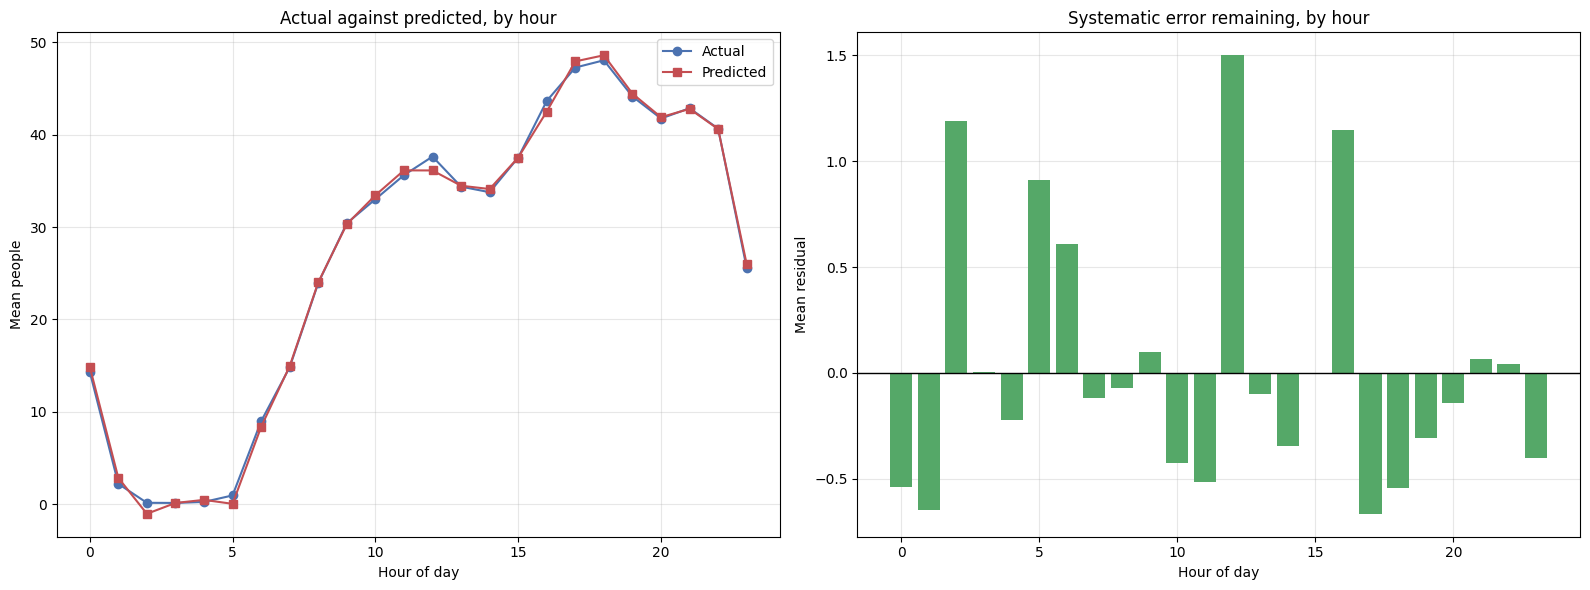


Largest absolute mean residual: 1.5 people, at hour 12


In [54]:
p_final = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
p_final.fit(Xb_train, yb_train)
pred_final = p_final.predict(Xb_test)
resid = yb_test - pred_final

err_by_hour = pd.DataFrame({'hour': gym['hour'].loc[yb_test.index], 'residual': resid.values,
                            'actual': yb_test.values, 'pred': pred_final})
hb = err_by_hour.groupby('hour').agg(mean_residual=('residual', 'mean'),
                                     mean_actual=('actual', 'mean'),
                                     mean_pred=('pred', 'mean'),
                                     n=('residual', 'size'))
print('Mean residual by hour of day (positive means under-predicting):')
print(hb.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(hb.index, hb['mean_actual'], marker='o', label='Actual', color='#4C72B0')
axes[0].plot(hb.index, hb['mean_pred'], marker='s', label='Predicted', color='#C44E52')
axes[0].set_xlabel('Hour of day'); axes[0].set_ylabel('Mean people')
axes[0].set_title('Actual against predicted, by hour')
axes[0].legend()

axes[1].bar(hb.index, hb['mean_residual'], color='#55A868')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Hour of day'); axes[1].set_ylabel('Mean residual')
axes[1].set_title('Systematic error remaining, by hour')
plt.tight_layout()
plt.show()

print()
print('Largest absolute mean residual:', round(hb['mean_residual'].abs().max(), 2),
      'people, at hour', int(hb['mean_residual'].abs().idxmax()))

## 10. Conclusions

### Scaling is the whole lesson

Same optimiser, same `eta0 = 1e-4`, same 50 epochs. The only difference is whether the features were standardised first:

| | RMSE | MAE | R-squared | Largest coefficient |
|---|---|---|---|---|
| Baseline: predict the training mean | 22.734 | 18.376 | -0.0000 | |
| **Closed-form OLS (reference)** | **15.830** | **12.090** | **0.5152** | 1.317e+01 |
| **SGD on unscaled features** | **diverged** | **diverged** | **diverged** | **5.171e+12** |
| SGD on scaled features | 15.844 | 12.109 | 0.5143 | 9.2128 |

The unscaled run did not merely perform badly, it **diverged**, with its largest single prediction reaching 4.467e+17 people in a gym whose observed maximum is 145. Its coefficients blew up to 5.17e+12. The scaled run, with every other setting identical, recovers **99.8% of the closed-form R-squared**.

The cause is measurable in the data. `timestamp` has a standard deviation of 24,211 and `is_holiday` has 0.051, a ratio of **477,917 to 1**. The gradient with respect to a feature is proportional to that feature's magnitude, so a step size stable along the `timestamp` axis is five orders of magnitude too small for the binary flags, and one large enough to move the flags overshoots along `timestamp` until the weights overflow. Standardising makes the loss surface round so a single step size works in every direction. The closed form never notices, which is why it sits in the table as the thing SGD is trying to reach.

### The learning rate window is narrow and the default is outside it

| eta0 | Test R-squared | Largest coefficient |
|---|---|---|
| 1e-7 | -0.6823 | 2.412 |
| 1e-6 | 0.5022 | 5.660 |
| 1e-5 | 0.5142 | 5.985 |
| **1e-4** | **0.5143** | 9.213 |
| 1e-3 | 0.5112 | 20.129 |
| 1e-2 | **diverged** | overflow |
| 0.1 | **diverged** | overflow |
| 1.0 | **diverged** | overflow |

The usable range spans roughly 1e-6 to 1e-3, and **scikit-learn's own default of `eta0=0.01` diverges on this data**. At 1e-7 the model is stable but has not moved far enough from zero in 50 epochs to beat the mean baseline, scoring -0.68. Both failure modes are silent: neither raises an exception, and a run that returns coefficients of 5e+12 looks like a fitted model unless someone checks.

On schedules, with `eta0 = 1e-4`:

| Schedule | Test R-squared |
|---|---|
| constant | 0.5143 |
| **optimal** | **diverged** |
| invscaling | 0.5141 |
| adaptive | 0.5143 |

`optimal` is the trap worth knowing: it **ignores `eta0` entirely**, setting the rate to 1 / (alpha * (t + t0)), so with the default `alpha=1e-4` the opening step is enormous no matter what was passed. Passing `eta0` alongside `learning_rate='optimal'` looks like configuration and does nothing at all.

### Convergence, watched rather than assumed

| Epoch | Test MSE |
|---|---|
| 1 | 251.2267 |
| 5 | 251.2241 |
| 10 | 251.0842 |
| 20 | 251.1319 |
| 40 | 251.0054 |
| 60 | 250.9550 |
| **Closed-form OLS** | **250.5929** |
| Mean baseline | 516.8491 |

Most of the work is done in the first epoch. From epoch 20 to epoch 60 the test MSE improves by 0.177, and a gap of 0.362 to the closed form still remains after 60 full passes. SGD approaches the exact solution asymptotically and does not reach it, which is the expected behaviour and not a bug.

Training and test curves sit on top of each other throughout. With 49,747 rows and 9 features there is no capacity to overfit, so early stopping would buy nothing; the only live question is whether it has converged.

### At this scale, SGD is a demonstration rather than a tool

| | Fit time |
|---|---|
| Closed-form OLS | **6.29 ms** |
| SGD, 50 epochs | 211.17 ms |

SGD is **33.6 times slower** on 49,747 rows and 9 features, and arrives at a slightly worse answer. That is the honest verdict for this dataset. The reason SGD matters is that its cost per step does not depend on the number of rows, so it keeps working when the matrix cannot be formed or inverted at all, and it can learn from a stream. None of those conditions holds here.

### Cyclical encoding helps; one-hot helps far more

| Feature set | Features | CV R-squared | std |
|---|---|---|---|
| A: raw, including both `timestamp` and `hour` | 9 | 0.5092 | 0.0034 |
| B: cyclical sine and cosine pairs | 11 | 0.5212 | 0.0023 |
| **C: hour as 24 indicators** | 33 | **0.6068** | 0.0026 |

The textbook cyclical fix is worth **+0.012**; replacing it with 24 hour indicators is worth a further **+0.086**, seven times more. The reason is visible in the occupancy-by-hour plot: the daily curve is not a sine wave. It climbs through the morning, plateaus across the afternoon and evening, then drops sharply overnight. One sine and cosine pair can only fit a single smooth oscillation, whereas 24 indicators can fit any shape at all. Cyclical encoding is the right default when the shape is roughly sinusoidal and there are too many levels to one-hot; with 24 levels and 62,000 rows, spending the parameters is clearly the better trade.

On the best feature set, Ridge and SGD are indistinguishable (R-squared 0.6090 both, MAE 10.849 against 10.848), while a random forest reaches **0.8782**. That gap of 0.27 R-squared is the share of the signal that is non-linear and therefore unreachable by any linear model however well optimised.

### The number that matters most: a random split was overstating everything by 1.17 R-squared

Every figure above comes from a random 80/20 split. This is a time series sampled every ten minutes, so consecutive rows are near-duplicates, and a random split puts 17:00:11 in training and 17:10:14 in test. The model is being graded on rows it has effectively already seen.

| Split | Ridge RMSE | Ridge R-squared | Mean-baseline R-squared | Train mean people | Test mean people |
|---|---|---|---|---|---|
| Random | 14.215 | **0.6090** | -0.0000 | 29.08 | 29.04 |
| **Chronological** | 18.320 | **-0.5575** | -1.0293 | 32.05 | 17.16 |

**Optimism from the random split: 1.1665 R-squared.** Trained on 2015-08-14 to 2016-10-26 and tested on 2016-10-26 to 2017-03-18, the model scores worse than predicting a constant. It is not a weak forecaster, it is an actively harmful one.

The reason is in the last two columns: the training period averaged 32.05 people and the test period averaged 17.16. The gym got substantially quieter, and the model learned a level that no longer applies. Note that the mean baseline also collapses to -1.0293 on this split, which confirms genuine distribution shift rather than a modelling failure: the training mean is simply the wrong answer for the later period.

Anyone reporting 0.6090 as this model's forecasting accuracy would be out by more than a full unit of R-squared. The random-split number is a valid measure of one thing only, interpolating occupancy within a period the model has already seen, and that is not a use case anyone wants.

### Limitations

- **The headline R-squared of 0.6090 is interpolation, not forecasting.** The chronological number of -0.5575 is the one that describes deployment, and it is the one a reader should take away.
- **The distribution shift is not diagnosed, only detected.** Whether occupancy fell because of a semester boundary, a facility change, a gym policy change or something else cannot be determined from these columns, and the fix (retraining on a rolling window, or adding a level or trend term) was not implemented.
- **`eta0` was tuned on the test set** in section 6. The sweep is a demonstration of the stability window rather than a legitimate model-selection procedure; a real tuning run belongs in cross-validation on the training fold.
- **The random forest was included only as a reference for the non-linear ceiling** and was not tuned, so 0.8782 is a floor on what a non-linear model could do, not an estimate of its best.
- **Observations are roughly ten minutes apart and strongly autocorrelated**, so the effective sample size is far smaller than 62,185 and the cross-validation standard deviations above are correspondingly optimistic.
- **`timestamp` and `hour` are redundant by construction**, and feature set A deliberately keeps both to make the scaling problem as stark as possible. That is a pedagogical choice, not a recommendation.
- **Zero occupancy appears in 14.11% of observations**, mostly overnight, so the target is mildly zero-inflated. A model that respected that boundary (a censored or two-stage specification) would be more appropriate than plain least squares, which happily predicts negative attendance.